# Correlator & operator API playground: E250, $P=(1,1,-1)$, $E^+$ row 2

A hands-on tour of `sigmondsamplings.correlators`, the correlator plots and the
fitting API on real data: one source/direction stream (`t01_fwd`) of the E250
$\rho$ channel at $P^2=3$, irrep $E^+$ row 2, as Sigmond bins (505 bins,
`HermMat` keys, no VEVs). See `docs/correlator_views_design.md` for the design.

| Section | API exercised |
| --- | --- |
| 1. Load | `SigmondLoader(lazy=True)`, run metadata |
| 2. Typed infos | `CorrelatorObsInfo` attributes, `filter`, `group_by` |
| 3. Labels | `parse_operator`, `BasicLapHOperator`, `Hadron`, `Channel`, `parse_key`, `CorrelatorAtTimeInfo`, `compact_str` |
| 4. Index & coverage | `loader.correlators`, `channels`, `coverage`, `plot_coverage`, `available_bases` |
| 5. Matrix assembly | `index.matrix`, error on incomplete basis, `sampling_info=`, `stored`, `key_form` |
| 6. Matrix views | `CorrelatorMatrixPlotter`: heatmaps, grid, summary; `normalized`, `significance` |
| 7. Single correlators | `index.correlator` vs `matrix.correlator`, `CorrelatorPlotter` |
| 8. Effective energies | `effective_energy` (four kinds, `step`, failure policies), `plot_diagonal(effective=True)` |
| 9. Hermiticity | `check_hermitian`, hermiticity heatmap |
| 10. Basis change | hand-rolled GEVP → `matrix.transform(T, GI ops)`, rotated effective energies |
| 11. Fitting | `SamplingFit.from_data`, `fit_full_sample` vs `fit_resampled`, `FitOverlay`, $t_{\min}$ scan, $\chi^2$ scan, batch fits, `FitResult` HDF5 round trip |
| 12. Round trip & CLI | `matrix.write` → reload; VEV errors; `ss query corr --plot` |

Every plot goes through `slat.plotting`: set `PLOT_BACKEND = "plotly"` in the first
cell for hover text (full operator names, values and errors). Sections are independent
after 1, 4 and 5 have run; the widgets use `ipywidgets.interact`.

In [1]:
from __future__ import annotations

import json
import tempfile
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path

import ipywidgets as W
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import sigmondsamplings as ss
import slat.plotting as slp
from sigmondsamplings import SamplingInfo, SigmondLoader
from sigmondsamplings.correlators import (
    BasicLapHOperator,
    Channel,
    CorrelatorAtTimeInfo,
    CorrelatorMatrixInfo,
    CorrelatorInfo,
    EffectiveEnergyWarning,
    GenIrrepOperator,
    Hadron,
    VEVInfo,
    effective_energy,
    effective_time_offset,
    parse_key,
    parse_operator,
)
from sigmondsamplings.plotting import (
    CorrelatorMatrixPlotter,
    CorrelatorPlotter,
    FitOverlay,
    HMarker,
    SeriesPlotter,
    SeriesStyle,
    plot_coverage,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110})
pd.set_option("display.max_colwidth", 90)

# "matplotlib" for static figures, "plotly" for hover text. Every plot below goes through slat.plotting.
PLOT_BACKEND = "plotly"
slp.use(PLOT_BACKEND)


def show(target):
    """Display a slat Axes or Figure on whichever backend is active (also inside widgets)."""
    (target.figure if isinstance(target, slp.Axes) else target).show()

HOME_DIR = Path.home()
DATA_DIR = HOME_DIR / Path("research/spectrum_analysis/rho_nolan/rho-ff-E250-corrs/extract_pSq3_Ep_20260928")
BINS_FILE = DATA_DIR / "E250_t01_fwd_P11m1_Ep_2_bins.hdf5"
RUN_META = json.loads((DATA_DIR / "E250_t01_fwd_P11m1_Ep_2_bins.json").read_text())
# The file's ensemble info carries no NTime, but effective energies need T: read it from the run's XML.
TIME_EXTENT = int(ET.parse(DATA_DIR / "e250_single_ensemble.xml").find(".//NTime").text)
TMP = Path(tempfile.mkdtemp(prefix="ss_corr_playground_"))
print(ss.__file__, "| T =", TIME_EXTENT, "| scratch dir:", TMP)

/Users/johnmeneghini/code/lqcd/sigmondsamplings/sigmondsamplings/__init__.py | T = 192 | scratch dir: /var/folders/s7/sl5m9m69097f4ywjtcymjsd40000gn/T/ss_corr_playground_0rb_orn6


## 1. Load the file lazily

`lazy=True` reads only metadata; samples are read on first use (a matrix
request reads just its cells, in one batched pass per file).

In [2]:
%time loader = SigmondLoader(str(BINS_FILE), lazy=True)
obs = loader.observables
print(type(obs).__name__, len(obs), "observables")
print("ensemble :", obs[0].ensemble_info)
print("kind     :", type(obs[0]).__name__, "| samples per obs:", obs[0].num_samples)
{k: RUN_META[k] for k in ("stream", "group", "ensemble", "nmeas", "number_of_bins", "hermitian", "subtract_vev")}

CPU times: user 201 ms, sys: 37 ms, total: 238 ms
Wall time: 435 ms
SingleEnsembleCollection 2520 observables
ensemble : EnsembleInfo('cls21_e250_r001', Nmeas = 1009, Nbins = 505, L = None, T = None)
kind     : LazySigmondBins | samples per obs: 505


{'stream': 't01_fwd',
 'group': 'P11m1_Ep_2',
 'ensemble': 'cls21_e250_r001',
 'nmeas': 1009,
 'number_of_bins': 505,
 'hermitian': True,
 'subtract_vev': False}

## 2. Correlators are typed observables

Every `<CorrT>` observable gets a `CorrelatorObsInfo`; its parsed key is exposed as
attributes, so the generic collection tools (`filter`, `group_by`, `sort`) work on
correlators with no correlator-specific code.

In [3]:
info = obs[0].observable_info
print(type(info).__name__)
print("name        :", info.name)
for attr in ("sink", "source", "time", "hermitian", "subtract_vev", "irrep", "psq", "momentum", "isospin", "strangeness"):
    print(f"{attr:12s}:", getattr(info, attr))
print("key         :", repr(info.key))

CorrelatorObsInfo
name        : <CorrT>BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} time=1 HermMat</CorrT>
sink        : isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]
source      : isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]
time        : 1
hermitian   : True
subtract_vev: False
irrep       : Ep
psq         : 3
momentum    : (1, 1, -1)
isospin     : triplet
strangeness : 0
key         : CorrelatorAtTimeInfo(correlator=CorrelatorInfo(sink=BasicLapHOperator('isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]'), source=BasicLapHOperator('isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]')), time=1, hermitian=True, subtract_vev=False)


In [4]:
at_t8 = obs.filter(obs_kind="correlator", time=8)
print(len(at_t8), "correlators at t=8  (11 ops -> 66 Hermitian pairs if complete)")

by_time = obs.group_by("time")
print("group_by('time'):", len(by_time), "groups; sizes:", sorted({len(v) for v in by_time.values()}))

by_sink = obs.group_by(lambda o: str(o.observable_info.sink))
pd.Series({k: len(v) for k, v in by_sink.items()}, name="# records with this sink").to_frame()

63 correlators at t=8  (11 ops -> 66 Hermitian pairs if complete)
group_by('time'): 40 groups; sizes: [63]


,# records with this sink
"isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]",280
"isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-2) A2m SS_0] [P=(2,1,1) A2m SS_0]",160
"isotriplet_pion_pion Ep_2 [P=(-1,-1,-1) A2m SS_0] [P=(2,2,0) A2m SS_0]",240
"isotriplet_pion_pion Ep_2 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]",320
"isotriplet_pion_pion Ep_2 [P=(-1,0,-2) A2m SS_0] [P=(2,1,1) A2m SS_0]",200
"isotriplet_pion_pion Ep_2 [P=(-1,0,0) A2m SS_1] [P=(2,1,-1) A2m SS_0]",40
"isotriplet_pion_pion Ep_2 [P=(-1,1,-1) A2m SS_0] [P=(2,0,0) A2m SS_1]",120
"isotriplet_pion_pion Ep_2 [P=(0,0,-1) A2m SS_1] [P=(1,1,0) A2m SS_0]",80
"pion P=(1,1,-1) Ep_2 SS_1",440
"pion P=(1,1,-1) Ep_2 VI_0",320


## 3. Operator labels and keys

Labels are frozen, hashable dataclasses. `str(op)` is Sigmond's canonical short
form and equality/hashing use `op.coordinate` (`BL{...}` / `GI{...}`).

In [5]:
rho_ss = parse_operator("pion P=(1,1,-1) Ep_2 SS_1")
pipi = parse_operator("isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]")

for op in (rho_ss, pipi):
    print(type(op).__name__, "|", op.coordinate)
    print("   hadrons :", op.hadrons)
    print("   channel :", op.channel)
    print("   isospin/irrep/row:", op.isospin, op.irrep, op.row, "| lg_cg:", op.lg_cg, "iso_cg:", op.iso_cg)
    print("   latex   :", op.latex_str)
    print("   compact :", op.compact_str, " (plot label; not guaranteed unique)")

BasicLapHOperator | BL{pion P=(1,1,-1) Ep_2 SS_1}
   hadrons : (Hadron(flavor='pion', momentum=(1, 1, -1), irrep='Ep', spatial_type='SS', spatial_id=1, displacement=0, color=None),)
   channel : isotriplet S=0 P=(1,1,-1) Ep_2
   isospin/irrep/row: None Ep 2 | lg_cg: 0 iso_cg: 0
   latex   : \pi(1,1,-1)\,E^{+}\,\mathrm{SS}_{1}
   compact : π(1,1,-1) SS1  (plot label; not guaranteed unique)
BasicLapHOperator | BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]}
   hadrons : (Hadron(flavor='pion', momentum=(-1, 0, -1), irrep='A2m', spatial_type='SS', spatial_id=0, displacement=0, color=None), Hadron(flavor='pion', momentum=(2, 1, 0), irrep='A2m', spatial_type='SS', spatial_id=0, displacement=0, color=None))
   channel : isotriplet S=0 P=(1,1,-1) Ep_2
   isospin/irrep/row: triplet Ep 2 | lg_cg: 1 iso_cg: 0
   latex   : \pi(-1,0,-1)\,\pi(2,1,0)\,E^{+}
   compact : ππ[(-1,0,-1),(2,1,0)] CG1  (plot label; not guaranteed unique)


Build the same operators by hand and check they compare/hash equal to the parsed ones.
Edit these to try other constructions — invalid combinations raise on construction.

In [6]:
rho_hand = BasicLapHOperator.single("pion", (1, 1, -1), "Ep", 2, "SS", 1)
pipi_hand = BasicLapHOperator(
    hadrons=(
        Hadron("pion", (-1, 0, -1), "A2m", "SS", 0),
        Hadron("pion", (2, 1, 0), "A2m", "SS", 0),
    ),
    irrep="Ep", row=2, isospin="triplet", lg_cg=1,
)
print(rho_hand == rho_ss, hash(rho_hand) == hash(rho_ss), str(rho_hand))
print(pipi_hand == pipi, str(pipi_hand))
print("Channel:",rho_ss.channel)
print("same channel:", rho_ss.channel == pipi.channel)
print("vacuum:", BasicLapHOperator.vacuum().coordinate, BasicLapHOperator.vacuum().is_vacuum)

# a GI label in the same channel (used for the basis change in section 10)
gi = GenIrrepOperator("triplet", 0, "Ep", "ROT", 0, momentum=(1, 1, -1), row=2)
print(gi.coordinate, "| channel matches:", gi.channel == rho_ss.channel)
print(parse_operator(gi.coordinate) == gi)

True True pion P=(1,1,-1) Ep_2 SS_1
True isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]
Channel: isotriplet S=0 P=(1,1,-1) Ep_2
same channel: True
vacuum: BL{} True
GI{isotriplet S=0 P=(1,1,-1) Ep_2 ROT 0} | channel matches: True
True


In [7]:
# Keys: parse the file's text, round trip, and flip the correlator.
key = parse_key(obs[5].observable_info.name)
print(type(key).__name__, "|", key)
print("sink  :", key.sink)
print("source:", key.source)
print("time/herm/subvev:", key.time, key.hermitian, key.subtract_vev)
print("to_sigmond():", key.to_sigmond())
print("round trip:", parse_key(key.to_sigmond()) == key, "| file text == to_sigmond():", key.to_sigmond() == obs[5].observable_info.name)
print("flipped:", key.flipped())
print("t -> 9 :", key.with_time(9))

corr = CorrelatorInfo(rho_ss, pipi)
print("corr:", corr, "| backwards:", corr.backwards)
print("corr.at(5, hermitian=True):", corr.at(5, hermitian=True).to_sigmond())
print("VEV key:", VEVInfo(rho_ss).to_sigmond())

# The reader also accepts the flags in either order and extra whitespace
messy = f"<CorrT>  {rho_ss.coordinate}   {pipi.coordinate} time=3 SubVEV HermMat </CorrT>"
print(parse_key(messy))

CorrelatorAtTimeInfo | BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} time=14 HermMat
sink  : isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]
source: isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]
time/herm/subvev: 14 True False
to_sigmond(): <CorrT>BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} time=14 HermMat</CorrT>
round trip: True | file text == to_sigmond(): True
flipped: BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} time=14 HermMat
t -> 9 : BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} t

In [8]:
# Try your own label here; bad labels raise SigmondParseError / ValueError with a reason
for text in ["pion P=(1,1,-1) Ep_2 SS_1", "pion P=(1,1,-1) Ep_7 SS_1", "notaflavor P=(0,0,0) A1um_1 SS_0"]:
    try:
        print("ok  :", parse_operator(text).coordinate)
    except Exception as exc:
        print("FAIL:", text, "->", type(exc).__name__, exc)

ok  : BL{pion P=(1,1,-1) Ep_2 SS_1}
ok  : BL{pion P=(1,1,-1) Ep_7 SS_1}
FAIL: notaflavor P=(0,0,0) A1um_1 SS_0 -> ValueError not a BL or GI operator string:
  as BL: unknown flavor 'notaflavor'
  as GI: unknown isospin 'notaflavor'


## 4. The `CorrelatorIndex`

`loader.correlators` builds (and caches) a metadata-only index: nothing here reads samples.

In [9]:
index = loader.correlators
print(index)
(channel, channel_ops), = index.channels.items()
print("channel:", channel, "| sector:", channel.to_sector())
print("times  :", index.times[0], "...", index.times[-1], "| sample length:", index.sample_length)
print("VEVs   :", index.vev_operators)
print("unparsed:", index.unparsed)

CorrelatorIndex(2520 correlators, 0 VEVs, 11 operators, 1 channels, times=1..40, bins)
channel: isotriplet S=0 P=(1,1,-1) Ep_2 | sector: SectorInfo(S=0, I=1)
times  : 1 ... 40 | sample length: 505
VEVs   : ()
unparsed: ()


In [10]:
# Order the operators as in the extraction run (opList), which is also the raw data order.
# compact_str is the plot label; hover text and tables keep the full str(op).
file_order = [parse_operator(s) for s in RUN_META["opList"]]
assert set(file_order) == set(channel_ops)
ALL_OPS = file_order
n = len(ALL_OPS)
pd.DataFrame({"compact_str": [o.compact_str for o in ALL_OPS], "operator": [str(o) for o in ALL_OPS]})

,compact_str,operator
0,"π(1,1,-1) SS1","pion P=(1,1,-1) Ep_2 SS_1"
1,"π(1,1,-1) VI0","pion P=(1,1,-1) Ep_2 VI_0"
2,"π(1,1,-1) VI1","pion P=(1,1,-1) Ep_2 VI_1"
3,"ππ[(-1,0,-1),(2,1,0)]","isotriplet_pion_pion Ep_2 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]"
4,"ππ[(-1,0,-1),(2,1,0)] CG1","isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]"
5,"ππ[(-1,-1,-1),(2,2,0)]","isotriplet_pion_pion Ep_2 [P=(-1,-1,-1) A2m SS_0] [P=(2,2,0) A2m SS_0]"
6,"ππ[(-1,0,-2),(2,1,1)]","isotriplet_pion_pion Ep_2 [P=(-1,0,-2) A2m SS_0] [P=(2,1,1) A2m SS_0]"
7,"ππ[(-1,0,-2),(2,1,1)] CG1","isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-2) A2m SS_0] [P=(2,1,1) A2m SS_0]"
8,"ππ[(-1,1,-1),(2,0,0)] SS0,SS1","isotriplet_pion_pion Ep_2 [P=(-1,1,-1) A2m SS_0] [P=(2,0,0) A2m SS_1]"
9,"ππ[(0,0,-1),(1,1,0)] SS1,SS0","isotriplet_pion_pion Ep_2 [P=(0,0,-1) A2m SS_1] [P=(1,1,0) A2m SS_0]"


### Coverage: which cells could a matrix read?

`index.coverage(ops)` answers, per time and cell, whether `matrix()` would find that
cell: the same key-form rules and Hermitian completion, but no samples read. Compare
with what the extraction run says was *measured* (`measured_orientation_snk_src`):
Sigmond's `HermMat` records keep one orientation per pair, so a pair with neither
orientation measured cannot be stored at all.

In [11]:
cov = index.coverage(ALL_OPS)            # bool xarray (time, sink, source); nothing read
print(cov.dims, cov.shape, "| key form:", cov.attrs["key_form"], "| times", int(cov.time[0]), "..", int(cov.time[-1]))

measured = np.array(RUN_META["measured_orientation_snk_src"])
either = (measured + measured.T) > 0
ticks = [o.compact_str for o in ALL_OPS]

fig = slp.figure(1, 2, figsize=(15, 6))
plot_coverage(cov, labels="short", axes=fig.axes(0, 0), title="stored: index.coverage (fraction of times)")
right = fig.axes(0, 1)
right.heatmap(np.where(either, 1.0, np.nan), cmap="viridis", vmin=0, vmax=1, origin="upper", colorbar=False)
right.ticks("x", range(n), ticks, rotation=45)
right.ticks("y", range(n), ticks)
right.set(title="measured, either orientation (run JSON)")
show(fig)
print("coverage agrees with the run's record:", np.array_equal(cov.values.any(axis=0), either))

('time', 'sink', 'source') (40, 11, 11) | key form: HermMat | times 1 .. 40


coverage agrees with the run's record: True


`available_bases` turns the coverage into the maximal sub-bases whose matrix is fully stored
(an exact search up to 16 operators), largest first. `ss query corr --matrix` uses it to
suggest `--ops` when cells are missing.

In [12]:
bases = index.available_bases(ALL_OPS)
for b in bases:
    print(len(b), [o.compact_str for o in b])

never = [
    (a.compact_str, b.compact_str)
    for i, a in enumerate(ALL_OPS)
    for b in ALL_OPS[i:]
    if not cov.sel(sink=a.coordinate, source=b.coordinate).any()
]
print("\nnever stored:", never)

9 ['π(1,1,-1) SS1', 'ππ[(-1,0,-1),(2,1,0)]', 'ππ[(-1,0,-1),(2,1,0)] CG1', 'ππ[(-1,-1,-1),(2,2,0)]', 'ππ[(-1,0,-2),(2,1,1)]', 'ππ[(-1,0,-2),(2,1,1)] CG1', 'ππ[(-1,1,-1),(2,0,0)] SS0,SS1', 'ππ[(0,0,-1),(1,1,0)] SS1,SS0', 'ππ[(-1,0,0),(2,1,-1)] SS1,SS0']

never stored: [('π(1,1,-1) VI0', 'π(1,1,-1) VI0'), ('π(1,1,-1) VI0', 'π(1,1,-1) VI1'), ('π(1,1,-1) VI1', 'π(1,1,-1) VI1')]


## 5. Assembling a correlation matrix

The whole channel can't be assembled: the `VI` operators' diagonals and the
`VI_0`/`VI_1` cross term were never measured. Nothing is zero-filled: the request
raises and names the missing cells. The largest available basis from `available_bases`
is what we use from here on.

In [13]:
try:
    index.matrix(ALL_OPS)
except ValueError as exc:
    print(str(exc)[:1200])

no time has every requested cell (key form 'HermMat'):
  time 1: missing (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_0}), (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_1}), (BL{pion P=(1,1,-1) Ep_2 VI_1}, BL{pion P=(1,1,-1) Ep_2 VI_0}) and 1 more
  time 2: missing (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_0}), (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_1}), (BL{pion P=(1,1,-1) Ep_2 VI_1}, BL{pion P=(1,1,-1) Ep_2 VI_0}) and 1 more
  time 3: missing (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_0}), (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_1}), (BL{pion P=(1,1,-1) Ep_2 VI_1}, BL{pion P=(1,1,-1) Ep_2 VI_0}) and 1 more
  time 4: missing (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_0}), (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_1}), (BL{pion P=(1,1,-1) Ep_2 VI_1}, BL{pion P=(1,1,-1) Ep_2 VI_0}) and 1 more
  time 5: missing (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,

In [14]:
BASIS = bases[0]                       # the largest available sub-basis, in ALL_OPS order

%time m_bins = index.matrix(BASIS)      # stays bins
print(m_bins)

SAMP_TYPE = 'J' # or 'B'
N_BS = 1000
SAMP_INFO = SamplingInfo.jackknife_for(index.ensemble_info) if SAMP_TYPE == 'J' else SamplingInfo.bootstrap(N_BS)
%time M = index.matrix(BASIS, sampling_info=SAMP_INFO)   # bins -> jackknife samplings
print(M)
print("values:", type(M.values).__name__, M.values.dims, M.values.shape, "| N samples:", M.values.num_samples)
print("key_form:", M.key_form, "| omitted_times:", M.omitted_times, "| channel:", M.info.channel)

CPU times: user 167 ms, sys: 33.9 ms, total: 201 ms
Wall time: 200 ms
CorrelatorMatrix(9x9, times=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40], hermitian, key form 'HermMat', bins)
CPU times: user 37.7 ms, sys: 22.1 ms, total: 59.8 ms
Wall time: 59.8 ms
CorrelatorMatrix(9x9, times=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40], hermitian, key form 'HermMat', SamplingInfo('jackknife', n=505, seed=0, boot_skip=0))
values: SigmondSampling ('time', 'sink', 'source') (40, 9, 9) | N samples: 506
key_form: HermMat | omitted_times: () | spec channel: isotriplet S=0 P=(1,1,-1) Ep_2


`M.stored[t, i, j]` is true where that ordered direction was itself in the file. For a
Hermitian request a cell whose direction wasn't stored is the conjugate of the flipped
one; the grid in section 6 draws those cells with hollow markers.

In [15]:
pd.DataFrame(M.stored.sel(time=5).values.astype(int), index=[o.compact_str for o in BASIS], columns=range(len(BASIS)))

,0,1,2,3,4,5,6,7,8
"π(1,1,-1) SS1",1,1,1,1,1,1,1,1,1
"ππ[(-1,0,-1),(2,1,0)]",0,1,1,1,1,1,1,1,1
"ππ[(-1,0,-1),(2,1,0)] CG1",0,0,1,1,1,1,1,1,1
"ππ[(-1,-1,-1),(2,2,0)]",0,0,0,1,1,1,1,1,1
"ππ[(-1,0,-2),(2,1,1)]",0,0,0,0,1,1,1,1,1
"ππ[(-1,0,-2),(2,1,1)] CG1",0,0,0,0,0,1,1,1,1
"ππ[(-1,1,-1),(2,0,0)] SS0,SS1",0,0,0,0,0,0,1,1,1
"ππ[(0,0,-1),(1,1,0)] SS1,SS0",0,0,0,0,0,0,0,1,1
"ππ[(-1,0,0),(2,1,-1)] SS1,SS0",0,0,0,0,0,0,0,0,1


In [16]:
# Other ways in: a spec, a sub-basis, a time window, strings instead of objects
spec = CorrelatorMatrixInfo(BASIS[:4], hermitian=True)
print(spec)
print(index.matrix(spec, times=range(3, 13), sampling_info=SAMP_INFO))
print(index.matrix([str(o) for o in BASIS[::-1]], times=[4, 8]))   # order is kept

# and the time errors are explicit, too:
try:
    index.matrix(BASIS, times=[5, 41])
except ValueError as exc:
    print("\n", exc)

CorrelatorMatrixInfo(operators=(BasicLapHOperator('pion P=(1,1,-1) Ep_2 SS_1'), BasicLapHOperator('isotriplet_pion_pion Ep_2 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]'), BasicLapHOperator('isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]'), BasicLapHOperator('isotriplet_pion_pion Ep_2 [P=(-1,-1,-1) A2m SS_0] [P=(2,2,0) A2m SS_0]')), hermitian=True, subtract_vev=False)
CorrelatorMatrix(4x4, times=[3, 4, 5, 6, 7, 8, 9, 10, 11, 12], hermitian, key form 'HermMat', SamplingInfo('jackknife', n=505, seed=0, boot_skip=0))
CorrelatorMatrix(9x9, times=[4, 8], hermitian, key form 'HermMat', bins)

 not every requested cell is stored at times [41] (key form 'HermMat'):
  time 41: missing (BL{pion P=(1,1,-1) Ep_2 SS_1}, BL{pion P=(1,1,-1) Ep_2 SS_1}), (BL{pion P=(1,1,-1) Ep_2 SS_1}, BL{isotriplet_pion_pion Ep_2 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]}), (BL{pion P=(1,1,-1) Ep_2 SS_1}, BL{isotriplet_pion_pion Ep_2 CG_1 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]}) and

## 6. Matrix views

A `CorrelatorMatrixPlotter` fixes one label and one colour per operator, so every view
of the matrix (heatmaps, grid, diagonal, effective energies) agrees. The heatmap values:

* **normalized**: $\tilde C_{ij}(t) = C_{ij}(t)/\sqrt{f_i f_j}$ with $f_i$ the full-sample
  $\mathrm{Re}\,C_{ii}(t_N)$, Sigmond's `TemporalCorrelatorMatrixRescaled`. $|\tilde C_{ij}(t_N)|$
  near 1 means operators $i$ and $j$ are nearly the same. $t_N$ defaults to the shown time.
* **significance**: $|C_{ij}|/\sigma_{ij}$, to spot noise-dominated cells.
* **hermiticity**: the `check_hermitian` residual in units of the error (section 9).

In [ ]:
# max_rel_error hides noise-dominated points (Sigmond's cut) and keeps them out of the autoscale
MP = CorrelatorMatrixPlotter(M, labels="short", style=SeriesStyle(max_rel_error=0.25))
TIMES = list(M.times)


def show_matrix(time=5, value="normalized", norm_time=None, component="real"):
    plotter = MP if component == "real" else CorrelatorMatrixPlotter(M, labels="short", component=component)
    show(plotter.plot_heatmap(time, value=value, norm_time=norm_time))

W.interact(
    show_matrix,
    time=W.SelectionSlider(options=TIMES, value=5),
    value=["normalized", "significance", "hermiticity"],
    norm_time=W.Dropdown(options=[("= time", None)] + [(str(t), t) for t in TIMES[:15]], value=None),
    component=["real", "imag"],
);

interactive(children=(SelectionSlider(description='time', index=4, options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11,…

In [18]:
# The numbers behind the heatmaps are ordinary SS objects
Cn = M.normalized(3)                       # SigmondData (time, sink, source): every sample / sqrt(f_i f_j)
print(type(Cn).__name__, Cn.dims, "| diagonal at tN:", np.round(np.diagonal(np.asarray(Cn.sel(time=3).full_sample_value)).real, 12))
sig = M.significance(20)                   # xarray (sink, source)
pd.DataFrame(sig.values.round(1), index=MP.operator_labels, columns=range(len(BASIS)))

SigmondSampling ('time', 'sink', 'source') | diagonal at tN: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


,0,1,2,3,4,5,6,7,8
"π(1,1,-1) SS1",6.5,4.3,1.1,4.1,1.2,2.1,3.0,5.2,6.3
"ππ[(-1,0,-1),(2,1,0)]",4.3,18.6,8.0,0.5,0.8,0.8,0.6,1.1,0.4
"ππ[(-1,0,-1),(2,1,0)] CG1",1.1,8.0,18.8,0.6,0.8,1.0,0.2,0.8,1.4
"ππ[(-1,-1,-1),(2,2,0)]",4.1,0.5,0.6,9.7,0.6,0.6,0.9,0.6,0.4
"ππ[(-1,0,-2),(2,1,1)]",1.2,0.8,0.8,0.6,3.2,1.4,0.9,1.1,0.7
"ππ[(-1,0,-2),(2,1,1)] CG1",2.1,0.8,1.0,0.6,1.4,4.7,0.8,1.0,0.8
"ππ[(-1,1,-1),(2,0,0)] SS0,SS1",3.0,0.6,0.2,0.9,0.9,0.8,28.6,1.9,1.1
"ππ[(0,0,-1),(1,1,0)] SS1,SS0",5.2,1.1,0.8,0.6,1.1,1.0,1.9,43.6,0.9
"ππ[(-1,0,0),(2,1,-1)] SS1,SS0",6.3,0.4,1.4,0.4,0.7,0.8,1.1,0.9,21.3


The grid: cell $(i, j)$ is $C_{ij}(t)$ (here normalized at $t_N=3$). Diagonal and
off-diagonal cells get separate y ranges, as in Sigmond; `diag_range=` / `offdiag_range=`
fix them. Hollow points came from the flipped direction.

In [19]:
show(MP.plot_grid(what="normalized", norm_time=3, figsize=(17, 14)))

In [20]:
# The same data through the SigmondData / xarray side
Ct = M.at(8)                                  # (sink, source) SigmondData at t=8
print(Ct.dims, Ct.shape)
c = M.sel(time=8, sink=BASIS[-1], source=BASIS[0])   # operator objects or strings work
print(f"C({BASIS[-1].compact_str} <- {BASIS[0].compact_str}) at t=8:", c.pdg_format())
print(M.at(8).to_real().mean.round(1))      # xarray over (sink, source)

('sink', 'source') (9, 9)
C(ππ[(-1,0,0),(2,1,-1)] SS1,SS0 <- π(1,1,-1) SS1) at t=8: 254.6(8.8) + 244.5(9.6)i
<xarray.DataArray (sink: 9, source: 9)> Size: 648B
array([[ 4.0900000e+01,  5.9020000e+02,  3.4000000e+00,  1.9830000e+02,
         3.5180000e+02, -9.6900000e+01,  3.7350000e+02,  5.7700000e+02,
         2.5460000e+02],
       [ 5.9020000e+02,  1.3574859e+06,  7.1179920e+05, -1.3836000e+04,
         3.4270000e+03, -1.7858000e+03,  4.9720000e+03, -8.2882200e+04,
         8.8269000e+03],
       [ 3.4000000e+00,  7.1179920e+05,  1.3817216e+06,  1.9845100e+04,
         7.0635000e+03, -3.0212000e+03,  3.0999000e+03,  5.8822900e+04,
        -4.1795000e+03],
       [ 1.9830000e+02, -1.3836000e+04,  1.9845100e+04,  2.3154650e+05,
         2.5440000e+02, -1.4096000e+03,  6.4830000e+03, -1.1565100e+04,
         6.3830000e+03],
       [ 3.5180000e+02,  3.4270000e+03,  7.0635000e+03,  2.5440000e+02,
         3.9658300e+05,  1.9531750e+05,  1.3587200e+04,  2.3090500e+04,
         5.5089000e+

## 7. Single correlators

`index.correlator(sink, source, hermitian=...)` reads one correlator directly; with
`hermitian=True` it may use the flipped key (by conjugation). It must agree with
the matrix cell.

In [21]:
sink, source = BASIS[-1], BASIS[2]
c_idx = index.correlator(sink, source, hermitian=True, sampling_info=SAMP_INFO)
c_mat = M.correlator(sink, source)
print(c_idx)
print("index == matrix cell:", np.allclose(np.asarray(c_idx.data), np.asarray(c_mat.data)))

c_flip = index.correlator(source, sink, hermitian=True, sampling_info=SAMP_INFO)
print("C_ji == conj(C_ij):", np.allclose(np.asarray(c_flip.data), np.conj(np.asarray(c_idx.data))))

# The VI operators still have their off-diagonal correlators with measured sources:
vi0 = parse_operator("pion P=(1,1,-1) Ep_2 VI_0")
print(index.correlator(vi0, BASIS[-1], hermitian=True))
try:
    index.correlator(vi0, vi0, hermitian=True)
except (ValueError, KeyError) as exc:
    print("VI_0 diagonal:", type(exc).__name__, str(exc)[:200])

SigmondSampling(name='correlator', shape=(40,), dims=('time',), N=506, ensemble='EnsembleInfo('cls21_e250_r001', Nmeas = 1009, Nbins = 505, L = None, T = None)')
index == matrix cell: True
C_ji == conj(C_ij): True
SigmondBins(name='correlator', shape=(40,), dims=('time',), N=505, ensemble='EnsembleInfo('cls21_e250_r001', Nmeas = 1009, Nbins = 505, L = None, T = None)')
VI_0 diagonal: ValueError no stored correlators for the requested operators in the allowed key forms 'HermMat', 'plain'


`CorrelatorPlotter` draws a correlator on a log axis (negative central values hollow at
$|C|$) above its effective energy, keyed where Sigmond plots it ($t + \mathrm{step}/2$
for the plain kinds). Off-diagonal correlators change sign, so their effective energies
fail at many samples: those points are simply not drawn.

In [22]:
op_choices = [(f"{i}: {o.compact_str}", o) for i, o in enumerate(ALL_OPS)]


def show_pair(sink=ALL_OPS[0], source=ALL_OPS[9], component="real", kind="forward", step=1, tmax=30):
    try:
        c = index.correlator(sink, source, hermitian=True, sampling_info=SAMP_INFO)
    except (ValueError, KeyError) as exc:
        print(type(exc).__name__, exc)
        return
    c = c.sel(time=[t for t in c.coords["time"] if t <= tmax])
    plotter = CorrelatorPlotter(c, component=component, labels=[f"{component} part"], style=SeriesStyle(max_rel_error=0.5))
    title = f"C({sink.compact_str} <- {source.compact_str})"
    try:
        show(plotter.plot_summary(kind=kind, step=step, time_extent=TIME_EXTENT, title=title))
    except ValueError as exc:                # e.g. no time with an effective energy
        print(exc)
        show(plotter.plot(title=title))


W.interact(
    show_pair,
    sink=W.Dropdown(options=op_choices, value=ALL_OPS[0]),
    source=W.Dropdown(options=op_choices, value=ALL_OPS[9]),
    component=["real", "imag"],
    kind=["forward", "symmetric", "forward_const", "symmetric_const"],
    step=W.IntSlider(1, 1, 4),
    tmax=W.IntSlider(value=30, min=8, max=40),
);

interactive(children=(Dropdown(description='sink', options=(('0: π(1,1,-1) SS1', BasicLapHOperator('pion P=(1,1,-1…

## 8. Effective energies

`effective_energy(corr, kind=, step=)` reproduces Sigmond's `EffectiveEnergyCalculator`
on every sample (full sample included), for any real `SigmondData` with a `time` dim;
other dims broadcast. The four kinds:

| kind | model | plotted at |
| --- | --- | --- |
| `forward` | $A e^{-mt}$ | $t + s/2$ |
| `symmetric` | $A(e^{-mt} + e^{-m(T-t)})$ | $t + s/2$ |
| `forward_const` | $A e^{-mt} + B_0$ | $t$ |
| `symmetric_const` | $A(e^{-mt} + e^{-m(T-t)}) + B_0$ | $t$ |

The result's `time` coord is the source time $t$ (so it `sel`s and fits like the
correlator); its `observable_info` records the kind, step and plot offset.

In [23]:
diag = M.diagonal(component="real")                                    # (time, operator), real
E_eff = effective_energy(diag, time_extent=TIME_EXTENT, on_fail="nan")  # forward, step 1
info = E_eff.observable_info
print(diag.dims, diag.shape, "->", E_eff.dims, E_eff.shape)
print(info, "| drawn at t +", info.time_offset, "=", effective_time_offset("forward", 1))
pd.Series(
    [E_eff.sel(time=10, operator=o.coordinate).pdg_format() for o in BASIS], index=MP.operator_labels, name="E_eff(t=10)"
).to_frame()

('time', 'operator') (40, 9) -> ('time', 'operator') (39, 9)
EffEn_forward_correlator_matrix 0 | drawn at t + 0.5 = 0.5


,E_eff(t=10)
"π(1,1,-1) SS1",0.2861(58)
"ππ[(-1,0,-1),(2,1,0)]",0.284(24)
"ππ[(-1,0,-1),(2,1,0)] CG1",0.282(21)
"ππ[(-1,-1,-1),(2,2,0)]",0.333(11)
"ππ[(-1,0,-2),(2,1,1)]",0.275(64)
"ππ[(-1,0,-2),(2,1,1)] CG1",0.355(13)
"ππ[(-1,1,-1),(2,0,0)] SS0,SS1",0.2776(76)
"ππ[(0,0,-1),(1,1,0)] SS1,SS0",0.1929(69)
"ππ[(-1,0,0),(2,1,-1)] SS1,SS0",0.2489(86)


In [24]:
# The four kinds, step 2, on the first operator. At these times T=192 is far away, so the
# symmetric kinds agree with the forward ones; the added-constant kinds are noisier.
def fmt(x):
    v, e = float(x.full_sample_value), float(x.error)
    return f"{v:.4f} ± {e:.4f}" if np.isfinite(v) and np.isfinite(e) else "failed"

first = diag.sel(operator=BASIS[0].coordinate)
table = {}
for kind in ("forward", "symmetric", "forward_const", "symmetric_const"):
    e = effective_energy(first, kind=kind, step=2, time_extent=TIME_EXTENT, on_fail="nan")
    table[kind] = {t: fmt(e.sel(time=t)) for t in (4, 8, 12, 16, 20)}
pd.DataFrame(table).rename_axis("t")

,forward,symmetric,forward_const,symmetric_const
t,,,,
4,0.3341 ± 0.0012,0.3341 ± 0.0012,0.4348 ± 0.0015,0.4348 ± 0.0015
8,0.2909 ± 0.0032,0.2909 ± 0.0032,0.3328 ± 0.0045,0.3328 ± 0.0045
12,0.2796 ± 0.0092,0.2796 ± 0.0092,0.2891 ± 0.0153,0.2891 ± 0.0153
16,0.2788 ± 0.0224,0.2788 ± 0.0224,0.3207 ± 0.0336,0.3207 ± 0.0336
20,0.2805 ± 0.0674,0.2805 ± 0.0674,0.3531 ± 0.1064,0.3531 ± 0.1064


**Failures.** Where a sample's ratio is not positive (or the cosh root can't be
bracketed), that sample fails. `on_fail="drop"` is Sigmond's rule (drop the time and
warn), `"nan"` keeps the time with NaN in the failed samples (what the plots use), and
`"raise"` raises and names the times.

In [25]:
n_failed = {o: int(np.isnan(np.asarray(E_eff.sel(operator=o.coordinate).data)).any(axis=-1).sum()) for o in BASIS}
worst = max(n_failed, key=n_failed.get)
print("times with a failed sample, per operator:", {o.compact_str: k for o, k in n_failed.items()})
series = diag.sel(operator=worst.coordinate)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", EffectiveEnergyWarning)
    dropped = effective_energy(series, time_extent=TIME_EXTENT)
kept = effective_energy(series, time_extent=TIME_EXTENT, on_fail="nan")
print(f"\n{worst.compact_str}:")
print("  drop :", len(dropped.coords["time"]), "times;", [str(w.message) for w in caught])
print("  nan  :", len(kept.coords["time"]), "times; failed samples at the last 5:",
      np.isnan(np.asarray(kept.data)).sum(axis=-1)[-5:].tolist())
try:
    effective_energy(series, time_extent=TIME_EXTENT, on_fail="raise")
except ValueError as exc:
    print("  raise:", exc)

times with a failed sample, per operator: {'π(1,1,-1) SS1': 6, 'ππ[(-1,0,-1),(2,1,0)]': 8, 'ππ[(-1,0,-1),(2,1,0)] CG1': 5, 'ππ[(-1,-1,-1),(2,2,0)]': 9, 'ππ[(-1,0,-2),(2,1,1)]': 11, 'ππ[(-1,0,-2),(2,1,1)] CG1': 14, 'ππ[(-1,1,-1),(2,0,0)] SS0,SS1': 3, 'ππ[(0,0,-1),(1,1,0)] SS1,SS0': 0, 'ππ[(-1,0,0),(2,1,-1)] SS1,SS0': 2}

ππ[(-1,0,-2),(2,1,1)] CG1:
  drop : 25 times; ['dropped times [25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]: the forward effective energy (step 1) fails there for some sample']
  nan  : 39 times; failed samples at the last 5: [502, 1, 506, 506, 3]
  raise: the forward effective energy (step 1) fails for some sample at times [25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


In [ ]:
basis_choices = [(f"{i}: {label}", o.coordinate) for i, (label, o) in enumerate(zip(MP.operator_labels, BASIS))]
coords = [o.coordinate for o in BASIS]


def show_eff(operators=(coords[0], coords[3], coords[-1]), kind="forward", step=1, tmax=25, max_rel_error=0.1):
    picks = [coords.index(c) for c in operators]
    sub = M.select(list(operators)).sel_times([t for t in M.times if t <= tmax + step])
    plotter = CorrelatorMatrixPlotter(          # same labels and colours as MP
        sub,
        labels=[MP.operator_labels[i] for i in picks],
        colors=[MP.operator_colors[i] for i in picks],
        style=SeriesStyle(max_rel_error=max_rel_error),
    )
    show(plotter.plot_diagonal(effective=True, kind=kind, step=step, time_extent=TIME_EXTENT,
                               title=f"diagonal effective energies ({kind}, step {step})"))


W.interact(
    show_eff,
    operators=W.SelectMultiple(options=basis_choices, value=(coords[0], coords[3], coords[-1]), rows=9),
    kind=["forward", "symmetric", "forward_const", "symmetric_const"],
    step=W.IntSlider(1, 1, 4),
    tmax=W.IntSlider(25, 5, 38),
    max_rel_error=W.FloatLogSlider(value=0.1, base=10, min=-2, max=0),
);

interactive(children=(SelectMultiple(description='operators', index=(0, 3, 8), options=(('0: π(1,1,-1) SS1', '…

In [27]:
# Everything about the matrix at a glance; the heatmaps are at t=3, normalized there
show(MP.plot_summary(panels=["diagonal", "effective_energy", "normalized", "significance"],
                     time=8, norm_time=3, time_extent=TIME_EXTENT)) 

## 9. Hermiticity check

`check_hermitian(tol)` compares $C_{ij}$ with $C_{ji}^*$ and the diagonal's imaginary
part, in units of the statistical error. This file stores `HermMat` records already averaged
by the extraction (one orientation per pair, real diagonals), so the residuals should be exactly
zero here — a useful sanity check that assembly doesn't break Hermiticity. Try it on a file with
both orientations stored to see real residuals.

In [28]:
h = M.check_hermitian(tol=3.0)
print("ok:", h.ok, "| max residual (sigma):", round(h.max_residual, 3))
show(MP.plot_heatmap(8, value="hermiticity"))

# Stricter: a non-Hermitian request can only use unflagged keys, and this file has none
try:
    index.matrix(BASIS, hermitian=False)
except ValueError as exc:
    print("\nhermitian=False:", exc)

ok: True | max residual (sigma): 0.0



hermitian=False: no stored correlators for the requested operators in the allowed key forms 'plain'; stored forms are 'HermMat' (set hermitian=/subtract_vev= to match)


## 10. Basis change: a hand-rolled fixed-pivot GEVP

`transform(T, new_ops)` gives $C' = T^\dagger C T$ on every sample. Here $T$ solves the
GEVP on the full sample at $(t_0, t_d)$:
$T = G^{-1/2} V$ with $G = C(t_0)$ and $V$ the eigenvectors of
$G^{-1/2} C(t_d) G^{-1/2}$, so that $C'(t_0) = 1$ and $C'(t_d)$ is diagonal.
The new operators must be GI labels in the same channel with a definite momentum.
(The built-in pivot is still an open item in the design doc — this is a test of `transform`.)

In [29]:
def gevp_rotation(mat, t0: int, td: int, rel_cut: float = 1e-10):
    # T (N_old, N_levels) from the full sample, levels ordered by decreasing eigenvalue.
    C = np.asarray(mat.values.full_sample_value)
    k0, kd = mat.times.index(t0), mat.times.index(td)
    G = 0.5 * (C[k0] + C[k0].conj().T)
    Cd = 0.5 * (C[kd] + C[kd].conj().T)
    g, U = np.linalg.eigh(G)
    keep = g > rel_cut * g.max()
    if not keep.all():
        print(f"metric rank cut: dropping {np.count_nonzero(~keep)} of {len(g)} directions")
    Ginv = U[:, keep] / np.sqrt(g[keep])            # G^{-1/2} restricted to the kept space
    lam, V = np.linalg.eigh(Ginv.conj().T @ Cd @ Ginv)
    order = np.argsort(lam)[::-1]
    return Ginv @ V[:, order], lam[order], g

def rotate(mat, t0, td, **kw):
    T, lam, g = gevp_rotation(mat, t0, td, **kw)
    new_ops = [GenIrrepOperator("triplet", 0, "Ep", "ROT", k, momentum=(1, 1, -1), row=2) for k in range(T.shape[1])]
    return mat.transform(T, new_ops), lam, g

t0, td = 4, 8
R, lam, g = rotate(M, t0, td)
print(R)
print("metric condition number:", f"{g.max() / g.min():.3g}")
Rt0 = np.asarray(R.at(t0).full_sample_value); Rtd = np.asarray(R.at(td).full_sample_value)
print("C'(t0) == 1:", np.allclose(Rt0, np.eye(len(Rt0)), atol=1e-8))
print("C'(td) diagonal:", np.allclose(Rtd - np.diag(np.diag(Rtd)), 0, atol=1e-8 * np.abs(Rtd).max()))
print("transformation stored:", R.transformation.coefficients.shape, "from", len(R.transformation.source_operators), "ops")
print("new operators:", [o.coordinate for o in R.operators[:2]], "...")

CorrelatorMatrix(9x9, times=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40], hermitian, SamplingInfo('jackknife', n=505, seed=0, boot_skip=0))
metric condition number: 5.07e+04
C'(t0) == 1: True
C'(td) diagonal: True
transformation stored: (9, 9) from 9 ops
new operators: ['GI{isotriplet S=0 P=(1,1,-1) Ep_2 ROT 0}', 'GI{isotriplet S=0 P=(1,1,-1) Ep_2 ROT 1}'] ...


In [30]:
def show_gevp(t0=4, td=8, ops=tuple(coords), kind="forward", tmax=25, max_rel_error=0.05):
    if td <= t0:
        print("need td > t0")
        return
    R, lam, g = rotate(M.select(list(ops)), t0, td)
    R = R.sel_times([t for t in R.times if t <= tmax + 1])
    plotter = CorrelatorMatrixPlotter(R, labels=[f"level {k}" for k in range(len(R))],
                                      style=SeriesStyle(max_rel_error=max_rel_error))
    axes = plotter.plot_diagonal(effective=True, kind=kind, time_extent=TIME_EXTENT,
                                 title=f"{len(ops)} ops, t0={t0}, td={td}, cond(G)={g.max() / g.min():.2g}")
    axes.axvline(t0, color="black", style=":", width=0.8)
    axes.axvline(td, color="black", style="--", width=0.8)
    show(axes)


W.interact(
    show_gevp,
    t0=W.IntSlider(4, 1, 15),
    td=W.IntSlider(8, 2, 20),
    ops=W.SelectMultiple(options=basis_choices, value=tuple(coords), rows=9),
    kind=["forward", "symmetric"],
    tmax=W.IntSlider(25, 8, 38),
    max_rel_error=W.FloatLogSlider(value=0.05, base=10, min=-3, max=0),
);

interactive(children=(IntSlider(value=4, description='t0', max=15, min=1), IntSlider(value=8, description='td'…

In [31]:
# transform() validation: wrong shapes, PSQ-only or wrong-channel labels are rejected
bad_cases = {
    "PSQ-only label": [GenIrrepOperator("triplet", 0, "Ep", "ROT", 0, momentum_squared=3, row=2)],
    "wrong row": [GenIrrepOperator("triplet", 0, "Ep", "ROT", 0, momentum=(1, 1, -1), row=1)],
    "BL label": [BASIS[0]],
}
T1 = np.eye(len(BASIS))[:, :1]
for what, ops in bad_cases.items():
    try:
        M.transform(T1, ops)
        print(what, ": accepted?!")
    except (ValueError, TypeError) as exc:
        print(f"{what:15s}: {type(exc).__name__}: {str(exc)[:110]}")

PSQ-only label : ValueError: GI{isotriplet S=0 PSQ=3 Ep_2 ROT 0}: a PSQ-only label is not a definite-momentum operator
wrong row      : ValueError: GI{isotriplet S=0 P=(1,1,-1) Ep_1 ROT 0} is not in the basis channel isotriplet S=0 P=(1,1,-1) Ep_2
BL label       : TypeError: new operators must be GI labels, got BasicLapHOperator('pion P=(1,1,-1) Ep_2 SS_1')


## 11. Fitting a rotated level

`SamplingFit.from_data(series, model, params)` fits a 1-D real `SigmondData` with an
`XModel`, using the series' `time` coord as $x$. The result keeps that $x$
(`FitResult.x` / `x_name`) and gives the model back labelled like the data
(`theory_series()`), which is what lets a fit be drawn over any correlator plot.

Two ways to get errors:

* `fit_full_sample()`: one fit, then Gaussian pseudo-resamples from the Jacobian
  covariance (`is_synthetic=True`). Fast; good for exploring windows.
* `fit_resampled()`: the full-sample fit, then one fit per jackknife sample.

In [32]:
from sigmondsamplings.fitting import (
    CallableXModel,
    CentralFit,
    FitResult,
    MinimizerConfig,
    ParamSetSpec,
    ParamSpec,
    ResampleBatch,
    SamplingFit,
    evaluate_chi2_scan,
)

R, lam, g = rotate(M, 4, 8)
R_diag = R.diagonal(component="real")
R_eff = effective_energy(R_diag, time_extent=TIME_EXTENT, on_fail="nan")
LEVELS = list(R_diag.coords["operator"])
LS = MinimizerConfig(algorithm="scipy_ls_trf")

one_exp = CallableXModel(lambda t, th: th[0] * np.exp(-th[1] * t), ("A", "E"))
two_exp = CallableXModel(
    lambda t, th: th[0] * np.exp(-th[1] * t) * (1 + th[2] * np.exp(-th[3] * t)), ("A", "E", "B", "dE")
)


def level_series(level, tmin, tmax):
    return R_diag.sel(operator=LEVELS[level]).sel(time=list(range(tmin, tmax + 1)))


def make_fit(level=0, tmin=10, tmax=24, model="1-exp", correlated=True):
    """A SamplingFit of one rotated level, started from its effective energy at tmin."""
    E0 = float(R_eff.sel(operator=LEVELS[level], time=tmin).full_sample_value)
    A0 = float(R_diag.sel(operator=LEVELS[level], time=tmin).full_sample_value) * np.exp(E0 * tmin)
    params = {"A": ParamSpec(initial=A0), "E": ParamSpec(initial=E0)}
    if model == "2-exp":
        params |= {"B": ParamSpec(initial=0.5), "dE": ParamSpec(initial=0.3, lower=0.0)}
    return SamplingFit.from_data(
        level_series(level, tmin, tmax),
        one_exp if model == "1-exp" else two_exp,
        ParamSetSpec(values=params).resolve(),
        minimizer=LS,
        use_correlation=correlated,
    )


def summary(name, res):
    print(f"{name:32s} aE = {res.param('E').pdg_format():14s} chi2/dof = {res.chi2_per_dof:5.2f}"
          f"   Q = {res.goodness_of_fit():.3f}   synthetic: {res.is_synthetic}")

In [33]:
fit = make_fit(level=0, tmin=10, tmax=24)
%time quick = fit.fit_full_sample()
%time full = fit.fit_resampled(backend="serial", progress=False)
summary("fit_full_sample (Jacobian)", quick)
summary("fit_resampled (505 fits)", full)
print("\nx kept on the result:", full.x_name, full.x)
full.theory_series()                  # the model at the fitted times, as a SigmondData over time

CPU times: user 19.1 ms, sys: 12.1 ms, total: 31.1 ms
Wall time: 33.6 ms
CPU times: user 1.07 s, sys: 0 ns, total: 1.07 s
Wall time: 1.07 s
fit_full_sample (Jacobian)       aE = 0.18531(73)    chi2/dof =  1.38   Q = 0.158   synthetic: True
fit_resampled (505 fits)         aE = 0.18531(74)    chi2/dof =  1.38   Q = 0.158   synthetic: False

x kept on the result: time [10. 11. 12. 13. 14. 15. 16. 17. 18. 19. 20. 21. 22. 23. 24.]


SigmondSampling(name='theory', shape=(15,), dims=('time',), N=506, ensemble='EnsembleInfo('cls21_e250_r001', Nmeas = 1009, Nbins = 505, L = None, T = None)')

### Fits on the correlator plots

`FitOverlay(result, energy="E")` draws a finished fit. On $C(t)$: the model band and
line over the fit range. On $E_\mathrm{eff}$: the energy parameter as a flat band, and
the **model's own effective energy** (the same `effective_energy` applied to
`theory_series()`, dashed). A single exponential is flat; a two-exponential fit shows
the excited-state curvature it claims.

In [34]:
two = make_fit(level=0, tmin=4, tmax=24, model="2-exp").fit_full_sample()
summary("2-exp [4, 24] (Jacobian)", two)

level0 = R_diag.sel(operator=LEVELS[0])
level0 = level0.sel(time=[t for t in level0.coords["time"] if t <= 30])
fits = [
    FitOverlay(full, energy="E", label="1-exp [10, 24]", color="#d60000"),
    FitOverlay(two, energy="E", label="2-exp [4, 24]", color="#1f6fd6"),
]
plotter = CorrelatorPlotter(level0, labels=["level 0"], colors=["black"], style=SeriesStyle(max_rel_error=0.2))
show(plotter.plot_summary(fits=fits, time_extent=TIME_EXTENT, title="rotated level 0"))

2-exp [4, 24] (Jacobian)         aE = 0.18362(85)    chi2/dof =  0.74   Q = 0.766   synthetic: True


Interactive fit window. Pick the level, window, model and error method, then hit
**Run Interact** (`resampled` runs 505 fits, a few seconds for one exponential).

In [35]:
def fit_level(level=0, tmin=10, tmax=24, model="1-exp", method="full sample", correlated=True):
    try:
        f = make_fit(level, tmin, tmax, model, correlated)
        res = f.fit_full_sample() if method == "full sample" else f.fit_resampled(backend="serial", progress=False)
    except Exception as exc:
        print(type(exc).__name__, exc)
        return
    summary(f"level {level} {model} [{tmin},{tmax}] ({method})", res)
    series = R_diag.sel(operator=LEVELS[level])
    series = series.sel(time=[t for t in series.coords["time"] if t <= tmax + 6])
    p = CorrelatorPlotter(series, labels=[f"level {level}"], style=SeriesStyle(max_rel_error=0.2))
    show(p.plot_summary(fits=[FitOverlay(res, energy="E", label=f"{model} [{tmin}, {tmax}]")], time_extent=TIME_EXTENT))
    return res


W.interact_manual(
    fit_level,
    level=W.IntSlider(0, 0, len(LEVELS) - 1),
    tmin=W.IntSlider(10, 2, 25),
    tmax=W.IntSlider(24, 8, 38),
    model=["1-exp", "2-exp"],
    method=["full sample", "resampled"],
    correlated=True,
);

interactive(children=(IntSlider(value=0, description='level', max=8), IntSlider(value=10, description='tmin', …

### Stability in $t_{\min}$

Fitted energies are single `SigmondSampling`s, so a scan stacks them into a
`SigmondData` over a `tmin` dim and `SeriesPlotter` draws it like any other series.
`HMarker.from_sampling` puts a reference fit on the same plot as a band.

In [36]:
tmins = list(range(4, 17))
scans = {}
for model, tmins_m in (("1-exp", tmins), ("2-exp", tmins[:6])):
    energies = [make_fit(0, t, 24, model).fit_full_sample().param("E") for t in tmins_m]
    scans[model] = ss.SigmondData.from_samplings(
        energies, obs_info=f"E0 {model}", dim_names=("tmin",), coords={"tmin": tmins_m}
    )

axes = SeriesPlotter(list(scans.values()), x="tmin", labels=list(scans)).plot(
    markers=[HMarker.from_sampling(full.param("E"), label="1-exp [10,24], resampled", color="#d60000")],
    xlabel=r"$t_{\min}$ ($t_{\max}=24$)",
    ylabel=r"$aE_0$",
)
show(axes)

### $\chi^2$ along one parameter

`evaluate_chi2_scan` evaluates the whitened $\chi^2$ of the fit's data over a parameter
stack. Here $E$ varies and $A$ is held at its best value, so this is a slice, not a
profile.

In [37]:
names = list(fit.param_set.names)
best = full.best_params
sigma_E = full.param("E").error
E_grid = np.linspace(best["E"] - 4 * sigma_E, best["E"] + 4 * sigma_E, 81)
bound = fit.objective.model           # the model, bound to the fitted times
chi2 = evaluate_chi2_scan(
    fit.objective.stats,
    lambda p: bound.predict(dict(zip(names, p))),
    varying_indices=[names.index("E")],
    varying_values=E_grid[:, None],
    fixed_params={names.index("A"): best["A"]},
    n_total_params=len(names),
)
axes = slp.figure(figsize=(7, 4)).axes()
axes.line(E_grid, chi2.chi2_values, color="black")
axes.axvline(best["E"], color="#d60000", style="--")
axes.axhline(full.chi2 + 1, color="0.5", style=":", label=r"$\chi^2_{\min} + 1$")
axes.set(xlabel="$aE$", ylabel=r"$\chi^2$", title="chi2 slice at the best A")
axes.legend()
show(axes)

### Batch fitting

`fit_resampled` is three steps that can run in different processes or scheduler jobs:
`prepare_resampled()` fits the full sample once (a portable `CentralFit`), `fit_indices`
fits any batch of resampling indices (a `ResampleBatch`), and `assemble_resampled` checks
and combines them. Both hand-off objects are JSON.

In [38]:
central = fit.prepare_resampled()
n_resamp = fit.sampling_info.num_resamplings
halves = [range(1, n_resamp // 2 + 1), range(n_resamp // 2 + 1, n_resamp + 1)]
%time batches = [fit.fit_indices(h, central=central, progress=False) for h in halves]

central.write(TMP / "central.json")
for k, batch in enumerate(batches):
    batch.write(TMP / f"batch_{k}.json")

# ... later, possibly elsewhere:
assembled = fit.assemble_resampled(
    CentralFit.read(TMP / "central.json"), [ResampleBatch.read(TMP / f"batch_{k}.json") for k in range(2)]
)
summary("assembled from 2 batches", assembled)
print("same samples as fit_resampled:", np.allclose(assembled.param("E").data, full.param("E").data))

CPU times: user 1.15 s, sys: 0 ns, total: 1.15 s
Wall time: 1.15 s
assembled from 2 batches         aE = 0.18531(74)    chi2/dof =  1.38   Q = 0.158   synthetic: False
same samples as fit_resampled: True


### Saving a fit

`write_params`, `write_chi2` and `write_theory` share one file; `x` and `x_name` ride
along on the theory group, so a fit read back from disk can still be overlaid.

In [39]:
path = TMP / "fit_level0.hdf5"
full.write_params(path, overwrite=True)
full.write_chi2(path, overwrite=True)
full.write_theory(path, overwrite=True)
loaded = FitResult.from_hdf5(path, chi2_file=path, theory_file=path, num_data_residuals=full.num_data_residuals)
print(loaded.x_name, loaded.x, "|", loaded.param("E").pdg_format())

show(plotter.plot_effective_energy(fits=[FitOverlay(loaded, energy="E", label="read back from disk")],
                                   time_extent=TIME_EXTENT))

time [10. 11. 12. 13. 14. 15. 16. 17. 18. 19. 20. 21. 22. 23. 24.] | 0.18531(74)


## 12. Round trips, VEVs and the CLI

`matrix.write` rebuilds each cell's `CorrT` key from the coords and spec, so a
rotated (GI) matrix writes and reads back like any other. Files go to `TMP`.

In [40]:
tmp = TMP

# (a) jackknife matrix of BL operators
M.write(tmp / f"matrix_{SAMP_INFO.method}.hdf5", group=SAMP_INFO.method)
idx2 = SigmondLoader(str(tmp / f"matrix_{SAMP_INFO.method}.hdf5")).correlators
M2 = idx2.matrix(BASIS)
print(idx2); print(M2)
print("values equal:", np.allclose(np.asarray(M2.values.data), np.asarray(M.values.data)))

# (b) bins sub-matrix stays bins
m_bins.select(BASIS[:3]).sel_times(range(1, 11)).write(tmp / "matrix_bins.hdf5", group="bins")
print(SigmondLoader(str(tmp / "matrix_bins.hdf5")).correlators)

# (c) rotated GI matrix
R.write(tmp / "rotated.hdf5", group="rot")
idx3 = SigmondLoader(str(tmp / "rotated.hdf5")).correlators
print(idx3)
print("GI operators:", [str(o) for o in idx3.operators[:3]], "...")
R3 = idx3.matrix(list(R.operators))
print("rotated values equal:", np.allclose(np.asarray(R3.values.data), np.asarray(R.values.data)))

# to_collection: per-cell observables with rebuilt keys
coll = R.to_collection()
print(len(coll), "observables; first key:", coll[0].observable_info.name)

CorrelatorIndex(3240 correlators, 0 VEVs, 9 operators, 1 channels, times=1..40, SamplingInfo('jackknife', n=505, seed=0, boot_skip=0))
CorrelatorMatrix(9x9, times=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40], hermitian, key form 'HermMat', SamplingInfo('jackknife', n=505, seed=0, boot_skip=0))
values equal: True
CorrelatorIndex(90 correlators, 0 VEVs, 3 operators, 1 channels, times=1..10, bins)
CorrelatorIndex(3240 correlators, 0 VEVs, 9 operators, 1 channels, times=1..40, SamplingInfo('jackknife', n=505, seed=0, boot_skip=0))
GI operators: ['isotriplet S=0 P=(1,1,-1) Ep_2 ROT 0', 'isotriplet S=0 P=(1,1,-1) Ep_2 ROT 1', 'isotriplet S=0 P=(1,1,-1) Ep_2 ROT 2'] ...
rotated values equal: True
3240 observables; first key: <CorrT>GI{isotriplet S=0 P=(1,1,-1) Ep_2 ROT 0} GI{isotriplet S=0 P=(1,1,-1) Ep_2 ROT 0} time=1 HermMat</CorrT>


In [41]:
# VEV subtraction: this file has no VEVs, so the request fails before reading any samples
for kw in ({"subtract_vev": True, "sampling_info": SAMP_INFO}, {"subtract_vev": True}):
    try:
        index.matrix(BASIS[:2], **kw)
    except (ValueError, KeyError) as exc:
        print(kw.keys(), "->", type(exc).__name__, ":", str(exc)[:300], "\n")

dict_keys(['subtract_vev', 'sampling_info']) -> ValueError : connected correlators derived from raw data need VEVs; missing for: BL{pion P=(1,1,-1) Ep_2 SS_1}, BL{isotriplet_pion_pion Ep_2 [P=(-1,0,-1) A2m SS_0] [P=(2,1,0) A2m SS_0]} 

dict_keys(['subtract_vev']) -> ValueError : connected correlators from bins need an explicit sampling_info: the raw correlators and VEVs are resampled jointly before subtracting 



`ss query corr --plot` draws exactly what the query selects. Operator numbers are the
CLI's `--operators` numbering (the index's first-seen order), so they are computed here.

BASIS as --ops: 8,7,0,2,3,1,5,6,4
┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ # ┃ channel                        ┃ n_operators ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 0 │ isotriplet S=0 P=(1,1,-1) Ep_2 │ 11          │
└───┴────────────────────────────────┴─────────────┘
│   time 8: missing (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_0}), (BL{pion P=(1,1,-1) Ep_2 VI_0}, BL{pion P=(1,1,-1) Ep_2 VI_1}), (BL{pion P=(1,1,-1) Ep_2 VI_1}, BL{pion P=(1,1,-1) Ep_2 VI_0}) and 1   │
│ more                                                                                                                                                                                                                     │
│ Pick an available sub-basis with --ops, e.g. --ops 0-8                                                                                                                                                                   │
╰─────────────────────────────────────

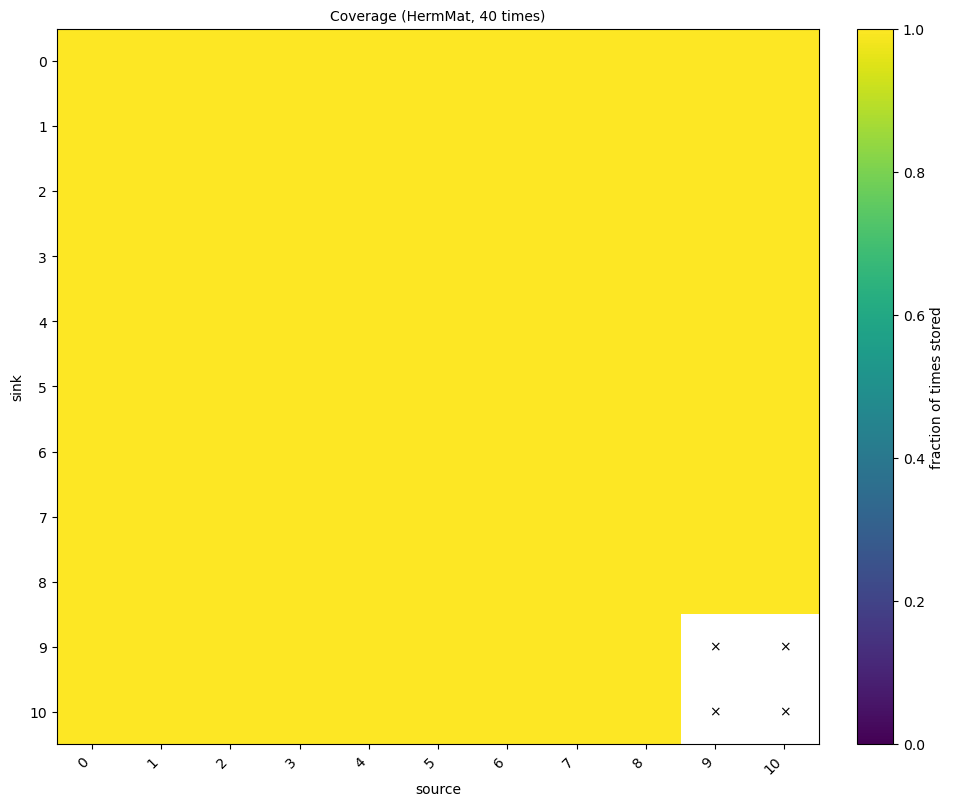

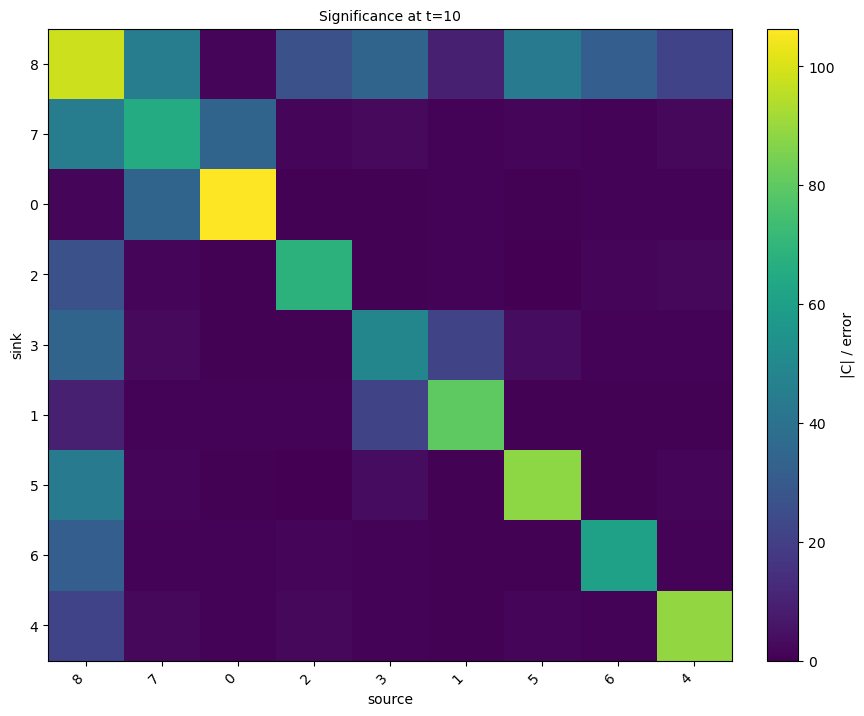

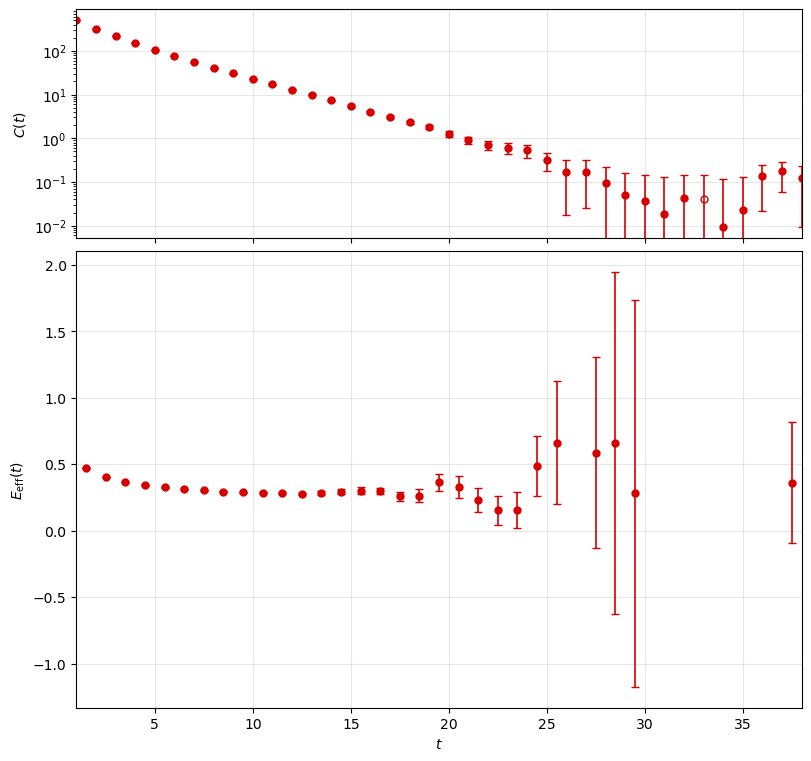

In [42]:
cli_numbers = ",".join(str(index.operators.index(o)) for o in BASIS)
sink_no = index.operators.index(BASIS[0])
print("BASIS as --ops:", cli_numbers)

!COLUMNS=220 ss query corr {BINS_FILE} --channels
!COLUMNS=220 ss query corr {BINS_FILE} --matrix 0 --time 8 2>&1 | tail -4
!ss query corr {BINS_FILE} --matrix 0 --plot coverage --no-gui --plot-output {TMP}/cli_coverage.png
!ss query corr {BINS_FILE} --matrix 0 --ops {cli_numbers} --plot heatmap --time 10 --plot-value significance --sampling jackknife --no-gui --plot-output {TMP}/cli_heatmap.png
!ss query corr {BINS_FILE} --sink {sink_no} --source {sink_no} --plot summary --eff-kind symmetric --time-extent {TIME_EXTENT} --sampling jackknife --no-gui --plot-output {TMP}/cli_pair.png
for name in ("cli_coverage", "cli_heatmap", "cli_pair"):
    display(Image(filename=str(TMP / f"{name}.png"), width=700))

## Scratch

Handy objects: `loader`, `index`, `ALL_OPS`, `BASIS`, `cov`, `M` (jackknife matrix),
`m_bins`, `MP` (its plotter), `diag`, `E_eff`, `R` (rotated), `R_diag`, `rotate`,
`make_fit`, `fit`, `full`, `quick`, `two`, `scans`, `TMP`.